# Import Library

In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# Data Clean Loading

In [8]:
df = pd.read_csv('../data/processed/supplier_clean.csv')

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24112 entries, 0 to 24111
Data columns (total 11 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Supplier_ID                      24112 non-null  object 
 1   Financial_Stability_Score        23800 non-null  float64
 2   On_Time_Delivery_Rate            23948 non-null  float64
 3   Defect_Rate                      23875 non-null  float64
 4   Geopolitical_Risk_Index          24112 non-null  int64  
 5   Lead_Time_Days                   23927 non-null  float64
 6   Alternative_Suppliers_Available  23895 non-null  float64
 7   Contract_Length_Months           24112 non-null  int64  
 8   Environmental_Compliance         23822 non-null  float64
 9   Previous_Disruptions             23953 non-null  float64
 10  Risk_Level                       24112 non-null  int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 2.0+ MB


# Train-Test Split

In [9]:
ids = df['Supplier_ID']
X = df.drop(columns=['Supplier_ID', 'Geopolitical_Risk_Index', 'Risk_Level'])
y = df['Risk_Level']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(X, y, ids, test_size=0.2, stratify=y, random_state=42)

# Cek Outliers

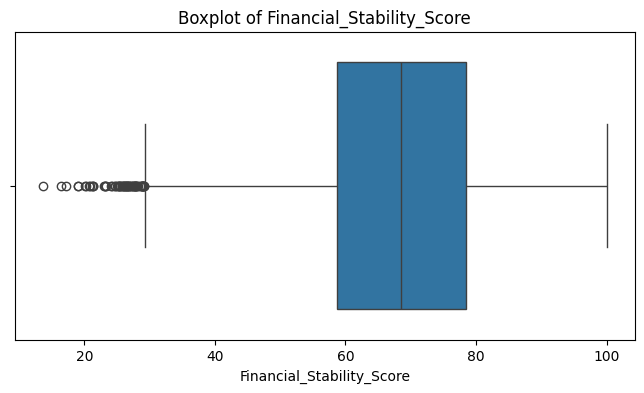

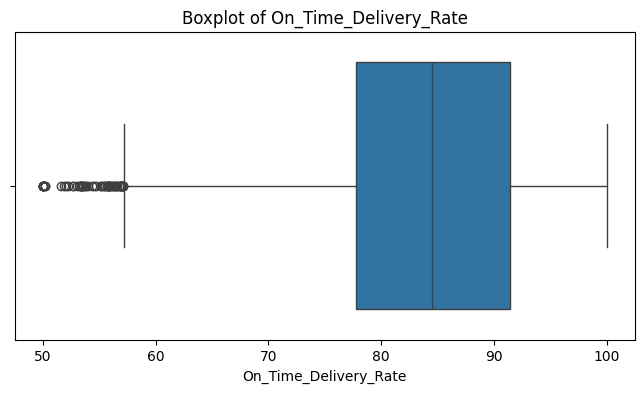

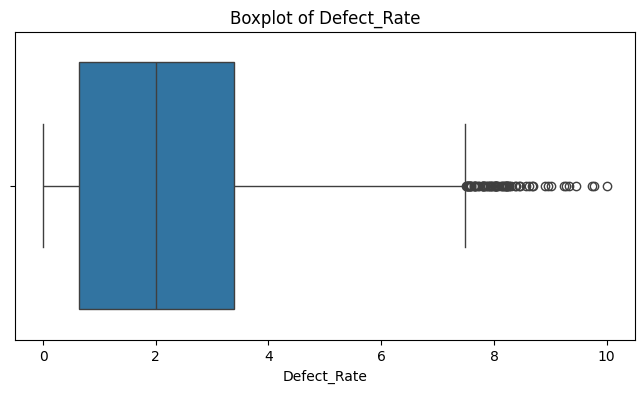

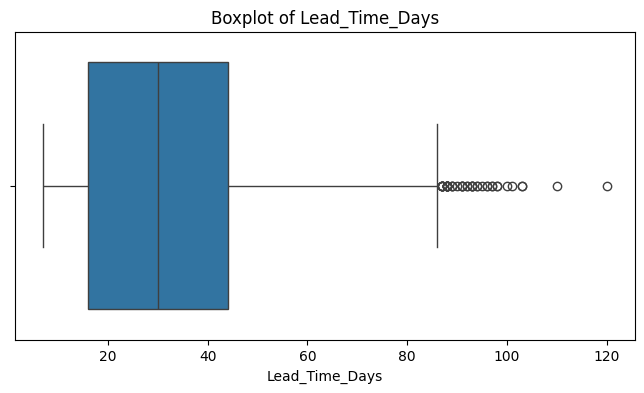

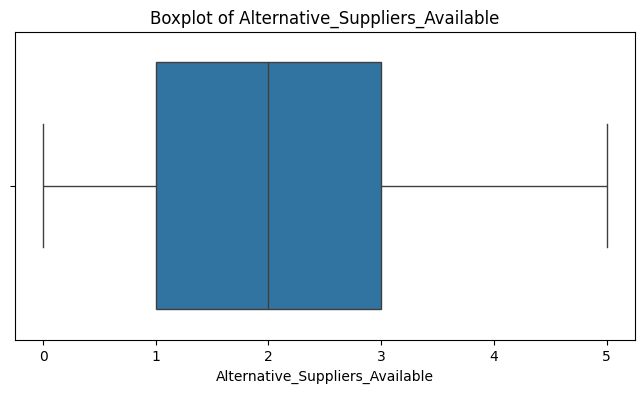

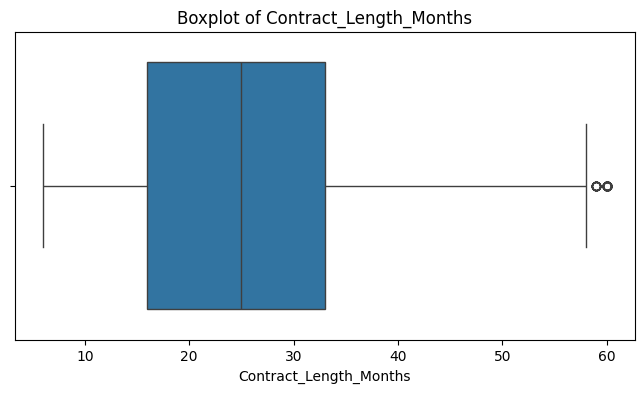

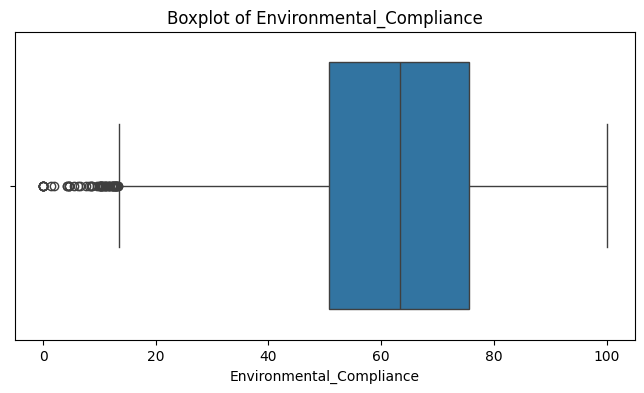

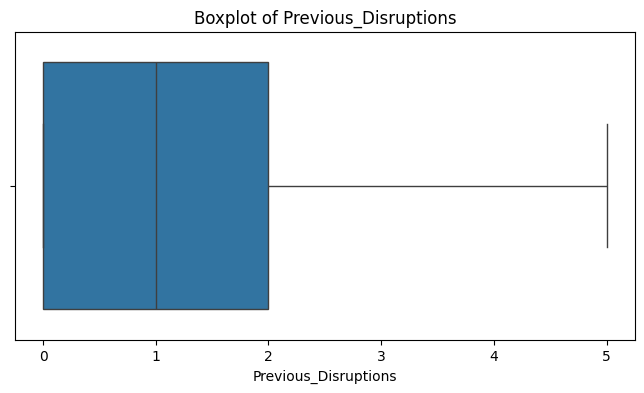

In [10]:
# Cek Outliers
for feature in X_train.columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=X_train[feature])
    plt.title(f'Boxplot of {feature}')
    plt.show()


# Simpan Hasil

In [11]:
os.makedirs('../data/processed', exist_ok=True)
X_train = pd.DataFrame(X_train, columns=X_train.columns)
X_test = pd.DataFrame(X_test, columns=X_test.columns)
y_train = pd.DataFrame(y_train).reset_index(drop=True)
y_test = pd.DataFrame(y_test).reset_index(drop=True)


X_train.to_csv('../data/processed/X_train.csv', index=False)
X_test.to_csv('../data/processed/X_test.csv', index=False)
y_train.to_csv('../data/processed/y_train.csv', index=False)
y_test.to_csv('../data/processed/y_test.csv', index=False)
id_test.to_csv('../data/processed/id_test.csv', index=False)